Background and Problem Statement

TagPro (https://tagpro.koalabeast.com/) is a free-to-play online 2-D capture the flag game in which players roll around a tiled map as paint-filled balls. Typically, the matches are played 4v4 with two players on each team on defense and the other two players on offense. While it can be a fun casual game, there is a staunch competitive community centered the game as well, not unlike the competitive scene around SSB Melee. Several regions (NA, EU, OCE) have professional leagues (MLTP, ELTP, OLTP respectively) where the best of the best battle it out to see who reigns supreme. There is a lot of raw data collected and recorded from each of these competitive matches, which are then reported either as is or used to construct more complex statistics. Going another step further, those statistics are then used to judge player performance, both directly by examining the leaders in each category and also by using comparison metrics that lump together several other statistics and weighting them appropriately.

This begs the question: "How do we choose the subcomponents of the player comparison metric in a reasonable manner, and subsequently weight them appropriately?" One reasonable approach to gathering information to this end is to use supervised learning algorithms to try to predict whether a player had a winning season based on their stats. We could define a winning season as having a positive cap differential; that is, the player's team scored more caps than they allowed their opponents to score against them. Figuring out which statistics are the most important for winning is crucial for players looking to improve their game, for general managers to decide which players they want to draft to their team, and for award voters to decide which players helped their teams the most.

Since the supervised investigation into that question was answered in the last investigation, we would like to now shift our attention to a related question and attempt to answer it using a bevy of unsupervised learning techniques coupled with the insight about which metrics are the most important from prior research. We would like to find players that are performing statistically far above or below the normal range in the statistical categories that have been determined to be the most relevant to winning using anomaly detection methods

We will look at data from the games of North American pro league, MLTP, spanning over two dozen seasons of matches. The data for each individual season is stored separately on a site called TagPro League, or TPL for short. We will need to scrape the raw data for each season and amalgamate everything, along with doing some non-trivial cleaning and preprocessing work.

[1] TagPro League. Available at: https://www.tagproleague.com/MLTP/stats (Accessed: April 22, 2023). 

In [125]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import warnings
import itertools
import plotly.express as px

A First Look at the Data

Let's examine the data we scraped from a single season of MLTP to get a better understanding of the underlying data structure and develop a plan for curating our final dataset.

In [126]:
warnings.filterwarnings('ignore', category = DeprecationWarning)
df = pd.read_csv('C:\\Users\\jshap\\OneDrive\\Desktop\\Stats\\MLTP_S10_majors_cumulative.tsv', delimiter = '\t', engine = 'python')
print(df)

           player team  score  minutes  pm  tags  pops  grabs  drops  hold  \
0         Altiger  NaN   1462      360   9   357   551    507    459  4078   
1      Blue Dream  NaN    143       40  -5    34    76     67     60   469   
2    Death Pickle  NaN   1579      400 -16   604   310    182    174  1461   
3         BigBird  NaN   1680      400  -4   550   284    170    158  1156   
4           Vials  NaN   1295      400 -16   286   645    594    542  4400   
..            ...  ...    ...      ...  ..   ...   ...    ...    ...   ...   
130       #Frozen  NaN     77       30 -19    31    66     57     54   227   
131       DUBSTEP  NaN     91       40 -28    28   102     83     77   353   
132     alchemist  NaN    105       40 -28    46    45     23     22   116   
133        Shabba  NaN     82       40 -28    29    74     60     57   276   
134  fenix funk 5  NaN    121       40 -28    59    53     26     26    82   

     ...  goodhandoff  goregrab  coregrab  gohandoff  cohandoff

We can see that there is no column to denote which season the data is from, so we will need to add that information into the master dataset as we weld the individual datasets together. By consulting with our Subject Matter Expert, we are also aware that there is an important shift that occurs starting in Season 20. Prior to that, most of the matches were played on teams' home servers, while in S20 and onwards all teams played on the Dallas-based server, resulting in much higher average ping for most players. To capture this critical rule change, we will also append a binary variable that tracks whether the season was played on Dallas or not.  

Building the Master Dataset

In [127]:
# Define the directory containing the TSV files
directory = 'C:\\Users\\jshap\\OneDrive\\Desktop\\Stats\\'

# Get a list of all TSV files in the directory
tsv_files = [os.path.join(directory, file) for file in os.listdir(directory) if file.endswith('.tsv')]

# Initialize an empty DataFrame to hold the data
MLTP_master_stats = pd.DataFrame()

# Loop over each TSV file and load it into a DataFrame
for i, location in enumerate(tsv_files):
    temp = pd.read_csv(location, sep = '\t', header = 0, na_values = [''], low_memory = False)
    season = i + 10
    Dallas = 0
    
    if season >= 20:
        Dallas = 1
    
    temp['Dallas'] = Dallas        
    temp['season'] = season
    MLTP_master_stats = MLTP_master_stats.append(temp, ignore_index=True)

# Convert necessary columns to factors
MLTP_master_stats['season'] = pd.Categorical(MLTP_master_stats['season'])
MLTP_master_stats['Dallas'] = pd.Categorical(MLTP_master_stats['Dallas'])

#Add ratio metrics (should NOT be per minute) 
MLTP_master_stats['kdr'] = MLTP_master_stats['tags'] / MLTP_master_stats['pops']
MLTP_master_stats['score_%'] = 100 * MLTP_master_stats['captures'] / MLTP_master_stats['grabs']

# Print the resulting DataFrame
print(MLTP_master_stats)
size = MLTP_master_stats.shape

            player team  score  minutes  pm  tags  pops  grabs  drops  hold  \
0          Altiger  NaN   1462      360   9   357   551    507    459  4078   
1       Blue Dream  NaN    143       40  -5    34    76     67     60   469   
2     Death Pickle  NaN   1579      400 -16   604   310    182    174  1461   
3          BigBird  NaN   1680      400  -4   550   284    170    158  1156   
4            Vials  NaN   1295      400 -16   286   645    594    542  4400   
...            ...  ...    ...      ...  ..   ...   ...    ...    ...   ...   
1307          Nati  TRT    159       50  10    65    50     40     39   186   
1308           bbb  ROJ    217       50   6    72    50     35     32   331   
1309          EIsa  NaN    165       50   3    34    86     83     74   472   
1310   TheEpicBlob  TGB    201       70   4    70    62     30     29   114   
1311       Pie Cat  NaN    196       50   8    54    69     63     54   426   

      ...  cohandoff  retinbase  quickret  saves  h

C:\Users\jshap\AppData\Local\Temp\ipykernel_10176\1497623423.py:21: FutureWarning:

The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.

C:\Users\jshap\AppData\Local\Temp\ipykernel_10176\1497623423.py:21: FutureWarning:

The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.

C:\Users\jshap\AppData\Local\Temp\ipykernel_10176\1497623423.py:21: FutureWarning:

The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.

C:\Users\jshap\AppData\Local\Temp\ipykernel_10176\1497623423.py:21: FutureWarning:

The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.

C:\Users\jshap\AppData\Local\Temp\ipykernel_10176\1497623423.py:21: FutureWarning:

The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.co

Now we have our full master dataset in all its glory! Let's investigate its properties a bit before getting ahead of ourselves with the data cleaning steps. We can see that we have 1312 observations, each containing 28 innate features and the four extra that we tacked on while creating the master dataset for a total of 32 features. The features 'Player' and 'team' are strings, 'Dallas' and 'season' are categorical features, 'Unnamed: 27' is a column full of all NaN values, and the other 27 features are various numeric integer statistical measures directly captured from the gameplay or calculated from directly captured data (such as Kill/Death Ratio and Scoring Percentage).

Data Cleaning

Let's programmatically check for missing values in each column for starters, in case the summary earlier didn't get the full picture:

In [128]:
for col in MLTP_master_stats.columns:
    temp = MLTP_master_stats[col].isna().sum()
    print(f"Missing values in feature '{col}': {temp} out of {size[0]}, or {round(100 * temp / size[0], 1)}% missing")

Missing values in feature 'player': 0 out of 1312, or 0.0% missing
Missing values in feature 'team': 1031 out of 1312, or 78.6% missing
Missing values in feature 'score': 0 out of 1312, or 0.0% missing
Missing values in feature 'minutes': 0 out of 1312, or 0.0% missing
Missing values in feature 'pm': 0 out of 1312, or 0.0% missing
Missing values in feature 'tags': 0 out of 1312, or 0.0% missing
Missing values in feature 'pops': 0 out of 1312, or 0.0% missing
Missing values in feature 'grabs': 0 out of 1312, or 0.0% missing
Missing values in feature 'drops': 0 out of 1312, or 0.0% missing
Missing values in feature 'hold': 0 out of 1312, or 0.0% missing
Missing values in feature 'captures': 0 out of 1312, or 0.0% missing
Missing values in feature 'prevent': 0 out of 1312, or 0.0% missing
Missing values in feature 'returns': 0 out of 1312, or 0.0% missing
Missing values in feature 'pups': 0 out of 1312, or 0.0% missing
Missing values in feature 'pupscomp': 0 out of 1312, or 0.0% missing
M

We can see that 'team' is missing almost 80% of its values, while 'Unnamed: 27' is entirely empty. There is no realistic way to impute values for either of these columns, so we will simply just drop them from the dataset entirely. Fortunately, almost every other column besides those two has exactly 0 missing values, so we are spared the effort of needing to impute anything at all. Note that there are a few missing values in the 'kdr' column, but we also know that 'kdr' is calculated directly from 'tags' divided by 'pops' and there is no missing data in either of those columns. What's going on here? A few of the players with a very low amount of minutes have 0 pops, which causes their KDR to became NaN due to a division by zero error. The same issue appears to plague the Scoring Percentage column as well, which would be expected if our hypothesis about why the data is missing is correct. We will circle back around to this after we filter out the players with too few minutes and we should see the missing values vanish.

In [129]:
MLTP_master_stats = MLTP_master_stats.drop(['team', 'Unnamed: 27'], axis = 1)
#print(MLTP_master_stats)

Another thing of importance to note from consultation with our SME is that different seasons had different numbers of weeks played, and some of the more recent seasons even had a different number of games and therefore minutes played each week. For a long time, the standard season length was 10 weeks with two 20 minute games a week for a total of 400 minutes played in a season. Season lengths started dropping down to around 7 weeks over time, and then in the past few seasons, the game format shifted from two 20 minute games to five 10 minute games a week. To handle this, we should temporally normalize all of these aggregation stats as per minute statistics instead.

In [130]:
MLTP_master_stats.columns

#Aggregation stats to be temporally normalized
agg_cols = ['score', 'pm', 'tags', 'pops', 'grabs', 'drops',
       'hold', 'captures', 'prevent', 'returns', 'pups', 'pupscomp',
       'flaccids', 'longholds', 'handoff', 'goodhandoff', 'goregrab',
       'coregrab', 'gohandoff', 'cohandoff', 'retinbase', 'quickret', 'saves',
       'holdagainst']

# Divide the columns by minutes played
MLTP_master_stats[agg_cols] = MLTP_master_stats[agg_cols].div(MLTP_master_stats['minutes'], axis = 0)

# Define a list of new column names
pm_cols = ['scorepm', 'successpm', 'tpm', 'poppm', 'gpm', 'dropspm',
       'hpm', 'cpm', 'ppm', 'rpm', 'puppm', 'pupscomppm',
       'flaccidspm', 'longholdspm', 'handoffpm', 'goodhandoffpm', 'goregrabpm',
       'coregrabpm', 'gohandoffpm', 'cohandoffpm', 'retinbasepm', 'quickretpm', 'savespm',
       'holdagainstpm']

# Create a dictionary of column name mappings
col_mapping = dict(zip(agg_cols, pm_cols))

# Rename the columns using the dictionary of column name mappings
MLTP_master_stats.rename(columns = col_mapping, inplace = True)

# Print the updated DataFrame
print(MLTP_master_stats)

            player   scorepm  minutes  successpm       tpm     poppm  \
0          Altiger  4.061111      360   0.025000  0.991667  1.530556   
1       Blue Dream  3.575000       40  -0.125000  0.850000  1.900000   
2     Death Pickle  3.947500      400  -0.040000  1.510000  0.775000   
3          BigBird  4.200000      400  -0.010000  1.375000  0.710000   
4            Vials  3.237500      400  -0.040000  0.715000  1.612500   
...            ...       ...      ...        ...       ...       ...   
1307          Nati  3.180000       50   0.200000  1.300000  1.000000   
1308           bbb  4.340000       50   0.120000  1.440000  1.000000   
1309          EIsa  3.300000       50   0.060000  0.680000  1.720000   
1310   TheEpicBlob  2.871429       70   0.057143  1.000000  0.885714   
1311       Pie Cat  3.920000       50   0.160000  1.080000  1.380000   

           gpm   dropspm        hpm       cpm  ...  gohandoffpm  cohandoffpm  \
0     1.408333  1.275000  11.327778  0.100000  ...     

On top of this, starting players will miss games and there will also be substitute players from the lower leagues filling in occasionally. We would like to exclude players that don't have many minutes played in a season, as they are likely either a minors player subbing or a majors player that got dropped for underperforming, either way not strong enough to be considered a majors level player. Additionally, a low number of minutes would make it more likely that their stats would be a huge outlier and throw off the model. Based on the recommendation of our SME, we will set this threshold as < 100 minutes played.  

In [131]:
# Filter out players with low minutes
MLTP_master_stats.drop(MLTP_master_stats[MLTP_master_stats['minutes'] <= 100].index, inplace = True)
print(MLTP_master_stats)

            player   scorepm  minutes  successpm       tpm     poppm  \
0          Altiger  4.061111      360   0.025000  0.991667  1.530556   
2     Death Pickle  3.947500      400  -0.040000  1.510000  0.775000   
3          BigBird  4.200000      400  -0.010000  1.375000  0.710000   
4            Vials  3.237500      400  -0.040000  0.715000  1.612500   
5          Mr.Gone  3.925000      400  -0.040000  1.392500  1.027500   
...            ...       ...      ...        ...       ...       ...   
1300         Messi  3.196000      250  -0.104000  0.764000  1.752000   
1301    BoldRoller  3.750000      268   0.070896  0.917910  1.727612   
1303         Prime  3.370000      200   0.100000  0.980000  1.150000   
1305  flaccid trip  3.887097      248  -0.129032  1.221774  1.120968   
1306            Ty  3.613445      238   0.096639  0.894958  1.218487   

           gpm   dropspm        hpm       cpm  ...  gohandoffpm  cohandoffpm  \
0     1.408333  1.275000  11.327778  0.100000  ...     

In [132]:
# Recheck dataframe
for col in MLTP_master_stats.columns:
    temp = MLTP_master_stats[col].isna().sum()
    print(f"Missing values in feature '{col}': {temp} out of {size[0]}, or {round(100 * temp / size[0], 1)}% missing")

Missing values in feature 'player': 0 out of 1312, or 0.0% missing
Missing values in feature 'scorepm': 0 out of 1312, or 0.0% missing
Missing values in feature 'minutes': 0 out of 1312, or 0.0% missing
Missing values in feature 'successpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'tpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'poppm': 0 out of 1312, or 0.0% missing
Missing values in feature 'gpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'dropspm': 0 out of 1312, or 0.0% missing
Missing values in feature 'hpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'cpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'ppm': 0 out of 1312, or 0.0% missing
Missing values in feature 'rpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'puppm': 0 out of 1312, or 0.0% missing
Missing values in feature 'pupscomppm': 0 out of 1312, or 0.0% missing
Missing values in feature 'flaccidspm': 0 out of 1312, or 0.0% missing
M

Now that all of the routine data cleaning has been executed, it's time to bring our SME knowledge into the fold. Based on the findings gleaned from previous research attempts, we are able to narrow down the list of statistics which are going to be the most interesting and relevant. Reducing the dimensionality of our data by excluding low importance statistical measures will cut out noise and eliminate some of the redundancy, which will make it easier for our models to find anomalies in critical areas. Let's do our routine EDA procdeures on the full feature set for a baseline look and then run the process again on the reduced set for comparison.

Exploratory Data Analysis

Now that our dataset is ready to go, we can start to investigate the data more thoroughly. Let's take a look at some of the statistics that are considered the most important by the MLTP community according to our SME. For defenders, the five most important stats are usually considered to be Tags, Returns, Prevent, Kill/Death Ratio, and Powerups. For offenders, the top five are generally believed to be Captures, Grabs, Hold, Scoring Percentage, and Powerups. On top off this, Score is a statistic built directly into the game's base code by the developer as his preferred agglomerative statistic.

We will start off looking at Prevent/Min vs Capture Differential/Min with the size of the data points representing 'score/min'. Score is the overall player evaluation statistic that is baked into the game by the developer, which is ignored entirely by the competitive community.

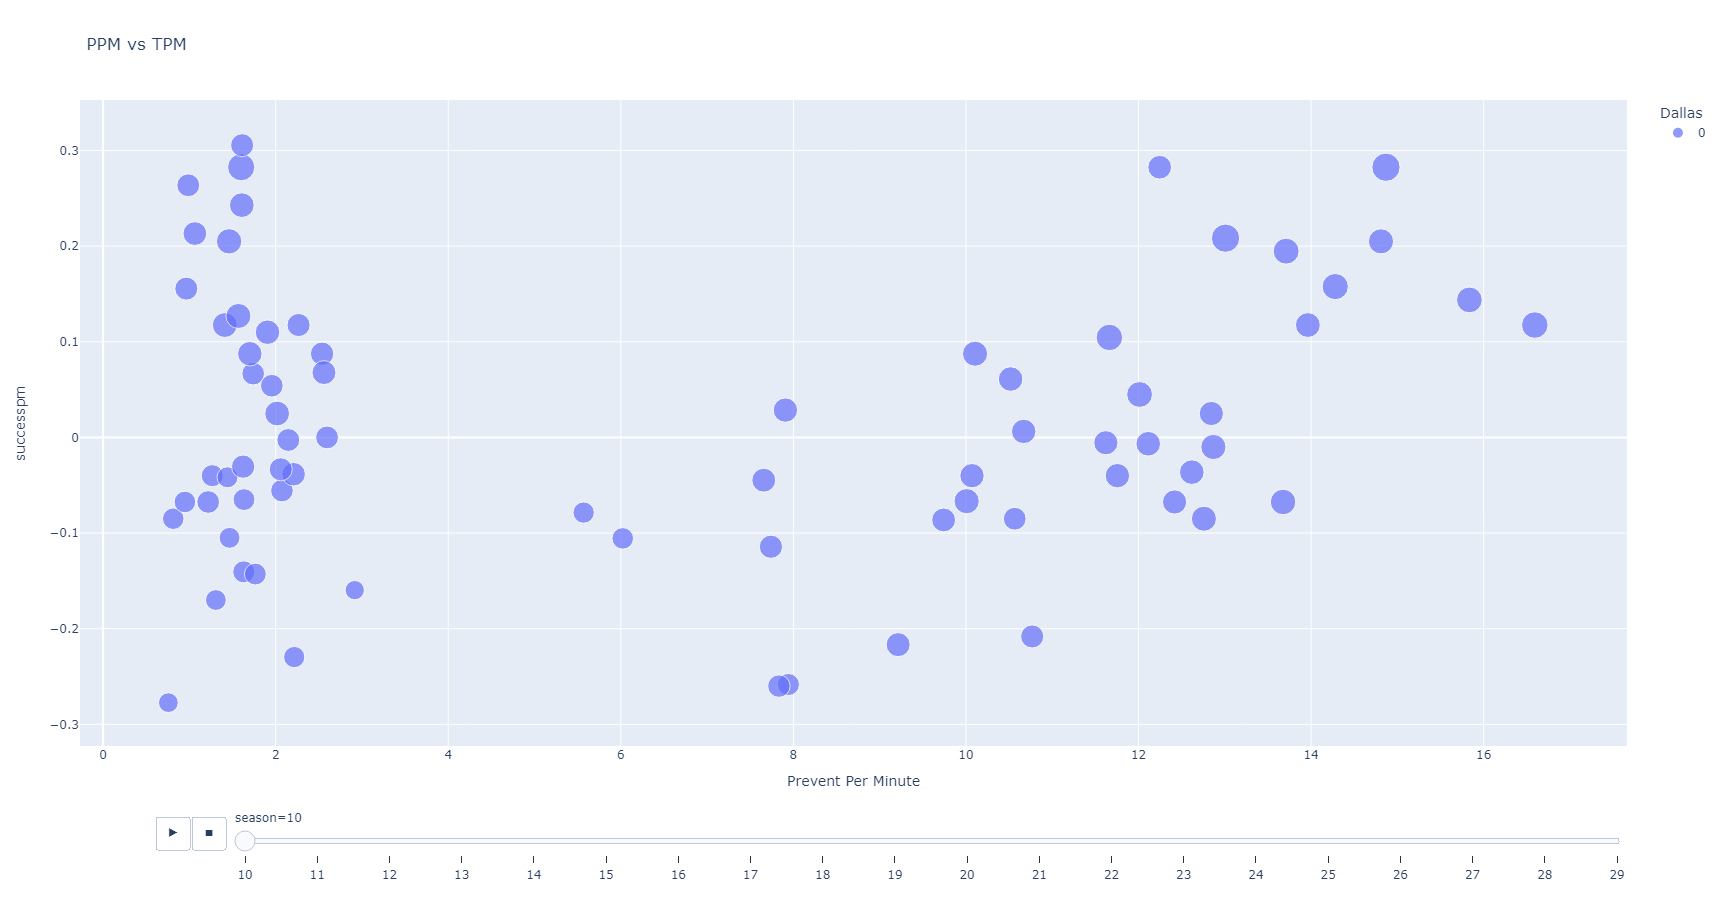

In [133]:
ppm_all = px.scatter(MLTP_master_stats, x = "ppm", y = "successpm",
size = "scorepm", color = "Dallas", animation_frame = "season",
hover_data = ["player"],
labels = {'ppm': 'Prevent Per Minute', 'tpm': 'Tags Per Minute'},
title = 'PPM vs TPM')

ppm_all.update_layout(scene=dict(xaxis=dict(title='Prevent Per Minute'),
yaxis=dict(title='Tags Per Minute')), height = 900)
ppm_all.show()

Looking at the plot for Season 10, which is the default plot that is displayed, we should immediately notice something strange about the shape of the data. There are two main clusters of data points, one of which forms a vertical cluster on the low end of the x axis, indicating that those players' success seems to be independent of their prevent per minute (PPM), while the other cluster of points follows more of a f(x) = cx shape with a weak to moderate positive correlation between PPM and success per minute. Why is this? Players that are offenders will almost always have very low prevent numbers, as they spend very little time in game defending their own flag while attending to their offense duties. Let's look at Hold, a statistic primarily earned by offenders, and confirm that we have a similar pattern.

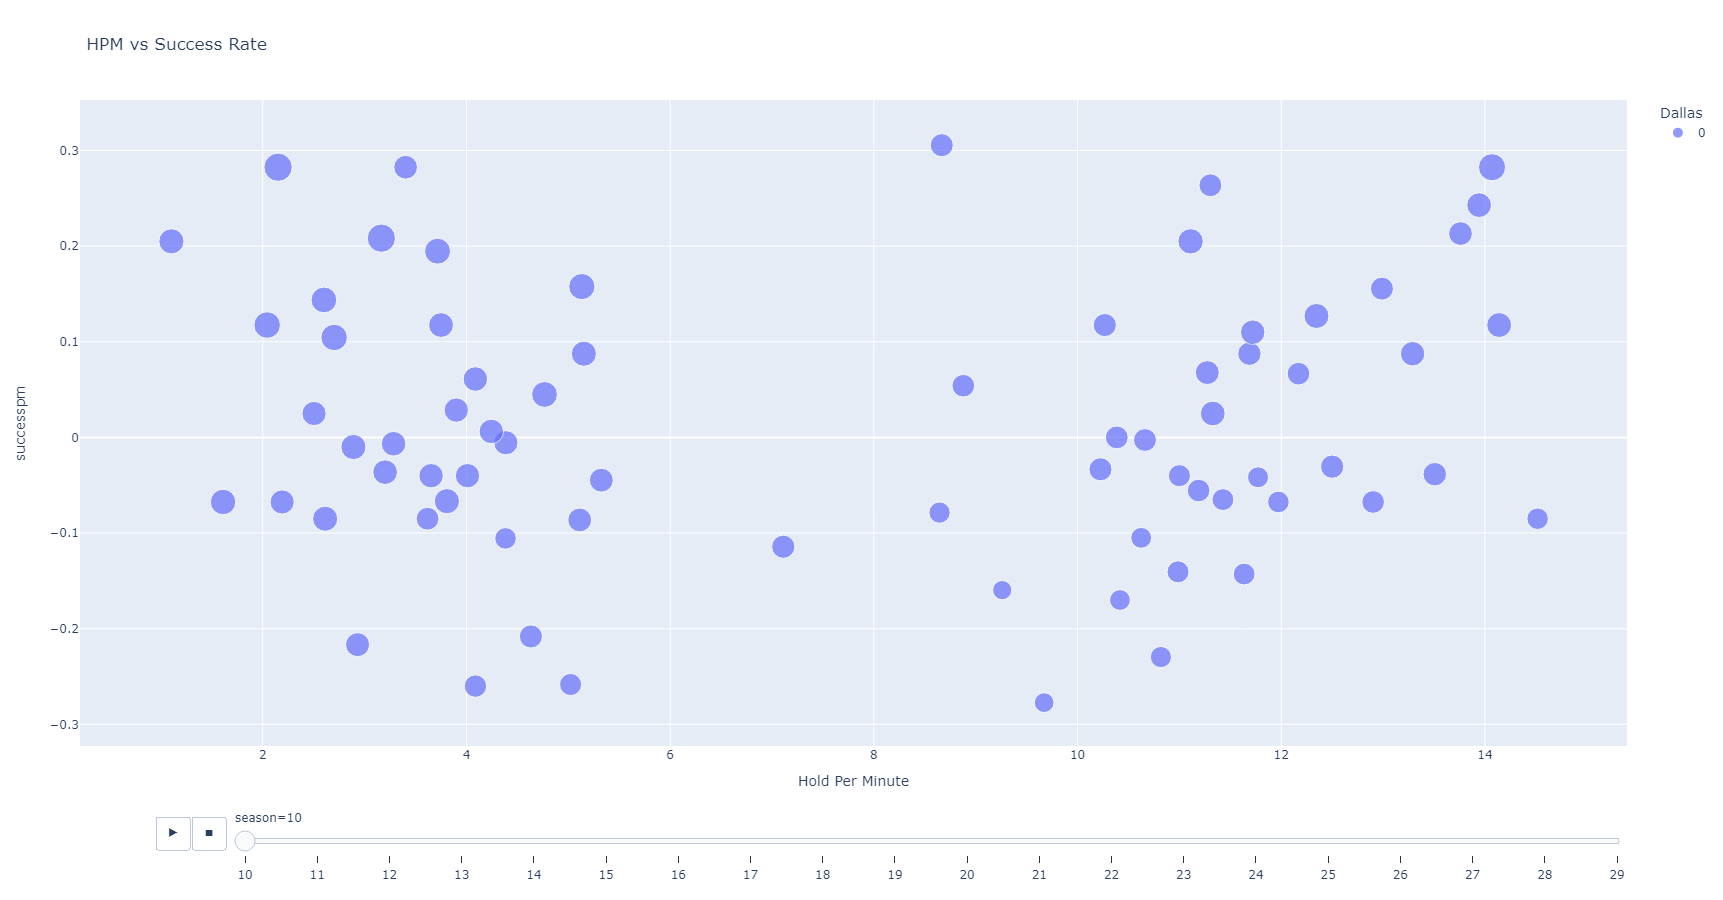

In [134]:
hpm_all = px.scatter(MLTP_master_stats, x = "hpm", y = "successpm",
size = "scorepm", color = "Dallas", animation_frame = "season",
hover_data = ["player"],
labels = {'hpm': 'Hold Per Minute', 'tpm': 'Tags Per Minute'},
title = 'HPM vs Success Rate')

hpm_all.update_layout(scene=dict(xaxis=dict(title='Hold Per Minute'),
yaxis=dict(title='Tags Per Minute')), height = 900)
hpm_all.show()

For Season 10 through 15, we again see this phenomenon of two main clusters of points, with the low values of hold having no correlation (the defenders) and the higher values of hold have a weak positive correlation (the offenders). Interestingly, there appears to be a fairly evenly spread, single cloud of points, with no indication of any correlation between hold and success for Season 16 onwards, which seems indicative that hold has not been an important statistic to consider for quite some time. This seemingly contradicts the widely held community belief that hold is one of the most important statistics to focus on for an offender.

Setting aside this shocking revelation about the importance of Hold for a moment, it becomes clear to us that we need to add some more information to the feature space. First, we need some way to differentiate between offenders and defenders; a successful model will certainly need to treat those as two separate populations if there are multiple features that are only predictive for one of the groups but not the other. While we're at it, we might as well create a binary attribute 'winner' that is 1 if the player has a positive cap differential and 0 otherwise. We will need this response variable both for training and testing the model.

Unfortunately, we don't have access to information on which position each player is playing, and some players will play a mix of both roles throughout a season. The best we can do is assign 'defender' to a player with higher prevent than hold and 'offender' to a player with higher hold than prevent. Irritatingly, sklearn does not handle categorical strings in a graceful manner, so for ease of model building we will just use a '0' for offense and a '1' for defense. 

In [135]:
# Adding in extra features
MLTP_master_stats['position'] = np.where(MLTP_master_stats['ppm'] > MLTP_master_stats['hpm'], 1, 0)
MLTP_master_stats['position'] = MLTP_master_stats['position'].astype('category')

MLTP_master_stats['winner'] = np.where(MLTP_master_stats['successpm'] > 0, 1, 0)
MLTP_master_stats['winner'] = MLTP_master_stats['winner'].astype('category')

MLTP_master_stats

,player,scorepm,minutes,successpm,tpm,poppm,gpm,dropspm,hpm,cpm,...,retinbasepm,quickretpm,savespm,holdagainstpm,Dallas,season,kdr,score_%,position,winner
0,Altiger,4.061111,360,0.025000,0.991667,1.530556,1.408333,1.275000,11.327778,0.100000,...,0.133333,0.111111,0.013889,30.463889,0,10,0.647913,7.100592,0,1
2,Death Pickle,3.947500,400,-0.040000,1.510000,0.775000,0.455000,0.435000,3.652500,0.017500,...,0.472500,0.412500,0.007500,31.052500,0,10,1.948387,3.846154,1,0
3,BigBird,4.200000,400,-0.010000,1.375000,0.710000,0.425000,0.395000,2.890000,0.015000,...,0.405000,0.365000,0.005000,30.040000,0,10,1.936620,3.529412,1,0
4,Vials,3.237500,400,-0.040000,0.715000,1.612500,1.485000,1.355000,11.000000,0.102500,...,0.097500,0.085000,0.007500,31.052500,0,10,0.443411,6.902357,0,0
5,Mr.Gone,3.925000,400,-0.040000,1.392500,1.027500,0.565000,0.530000,4.010000,0.032500,...,0.432500,0.335000,0.007500,31.052500,0,10,1.355231,5.752212,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1300,Messi,3.196000,250,-0.104000,0.764000,1.752000,1.684000,1.532000,10.972000,0.152000,...,0.160000,0.128000,0.020000,29.772000,1,29,0.436073,9.026128,0,0
1301,BoldRoller,3.750000,268,0.070896,0.917910,1.727612,1.473881,1.339552,10.167910,0.126866,...,0.205224,0.227612,0.003731,25.104478,1,29,0.531317,8.607595,0,1
1303,Prime,3.370000,200,0.100000,0.980000,1.150000,0.775000,0.715000,3.665000,0.050000,...,0.290000,0.270000,0.010000,27.620000,1,29,0.852174,6.451613,1,1
1305,flaccid trip,3.887097,248,-0.129032,1.221774,1.120968,0.931452,0.842742,7.483871,0.072581,...,0.395161,0.338710,0.004032,26.661290,1,29,1.089928,7.792208,1,0


Next, let's check the correlation strength between the features to see if there are any highly correlated variables.

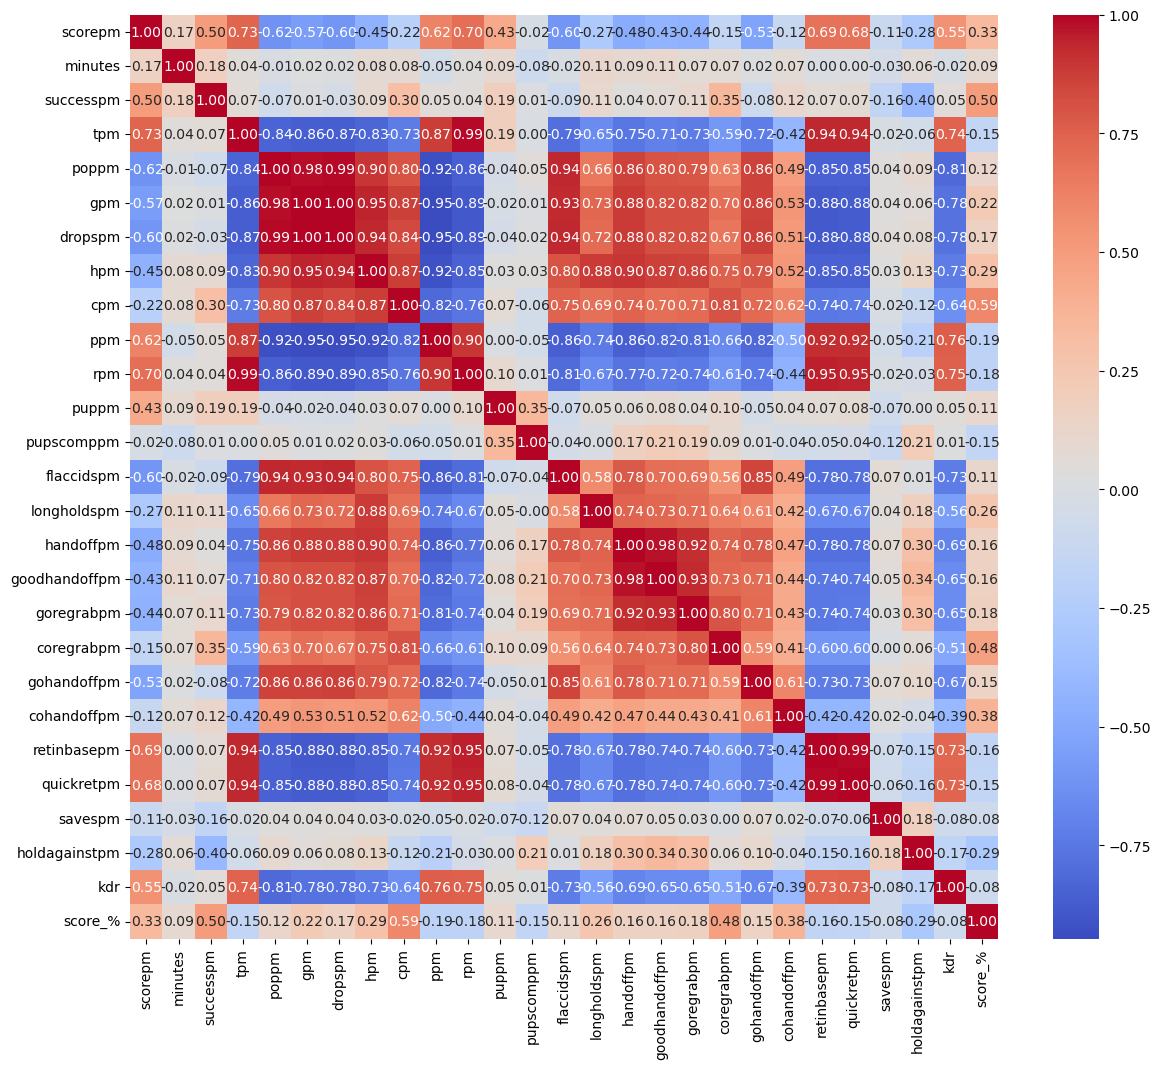

In [136]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = MLTP_master_stats.corr(numeric_only = True)
plt.figure(figsize = (14, 12))
sns.heatmap(corr_matrix, annot = True, fmt = '.2f', cmap = 'coolwarm')
plt.show()

Clearly there are several groups of highly correlated features, but this isn't inherently an issue depending on what kind of unsupervised learning method we use going forward. Let's check for collinearity as well while we're at it.

In [137]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select only the numeric features
numeric_cols = MLTP_master_stats.select_dtypes(include = ['int64', 'float64']).columns
numeric_cols = numeric_cols.delete(numeric_cols.get_loc('successpm'))

print(numeric_cols)

# Create a DataFrame to store the VIF values
MLTP_vif = pd.DataFrame(columns = ['feature', 'VIF'])

# Calculate the VIF for each feature and insert into VIF df
for i, col in enumerate(numeric_cols):
    vif = variance_inflation_factor(MLTP_master_stats[numeric_cols].values, i)
    MLTP_vif.loc[i] = [col, vif]

# View the VIF DataFrame
print(MLTP_vif)

Index(['scorepm', 'minutes', 'tpm', 'poppm', 'gpm', 'dropspm', 'hpm', 'cpm',
       'ppm', 'rpm', 'puppm', 'pupscomppm', 'flaccidspm', 'longholdspm',
       'handoffpm', 'goodhandoffpm', 'goregrabpm', 'coregrabpm', 'gohandoffpm',
       'cohandoffpm', 'retinbasepm', 'quickretpm', 'savespm', 'holdagainstpm',
       'kdr', 'score_%'],
      dtype='object')
          feature           VIF
0         scorepm    496.288716
1         minutes     18.677807
2             tpm    703.645791
3           poppm    682.783695
4             gpm  30697.788394
5         dropspm  26295.206374
6             hpm    612.889955
7             cpm    336.239309
8             ppm     55.421083
9             rpm    567.887786
10          puppm     56.675337
11     pupscomppm    207.667717
12     flaccidspm    110.028657
13    longholdspm     48.572062
14      handoffpm    202.576212
15  goodhandoffpm    147.953609
16     goregrabpm     53.892869
17     coregrabpm     16.656591
18    gohandoffpm     25.944345
19 

Most of the features have a Variance Inflation Factor significantly higher than 5, which is the standard cutoff for excluded features from multilinear regression. If only a few had a high VIF, we could prune those out and use linear modeling methodologies but that is untenable in a situation where only two of the features have a VIF < 5. We will need to use a nonlinear modeling approach that is robust against highly correlated and collinear data. 

Now that we have run through standard operating procedure EDA, let's incorporate the feature selection based on SME knowledge and research results as mentioned earlier. The two main actions we must carry out are cutting down on the feature space dimensionality and seperating the master dataset into two segments, one for players that primarily played defense and the other for players that primarily played offense. Prior exploration saw models struggle somewhat to deal with both types of players lumped together into one population, chiefly due to the fact that we were trying to predict whether a player had a winning season or not, and the tasks that a defender and an offender must focus on to win are very different.

In [138]:
# Remove columns with little value or high collinearity
MLTP_pruned = MLTP_master_stats.drop(columns = ['pupscomppm', 'flaccidspm', 'longholdspm',
       'handoffpm', 'goodhandoffpm', 'goregrabpm', 'coregrabpm', 'gohandoffpm',
       'cohandoffpm', 'retinbasepm', 'quickretpm', 'savespm', 'holdagainstpm'])
MLTP_pruned

,player,scorepm,minutes,successpm,tpm,poppm,gpm,dropspm,hpm,cpm,ppm,rpm,puppm,Dallas,season,kdr,score_%,position,winner
0,Altiger,4.061111,360,0.025000,0.991667,1.530556,1.408333,1.275000,11.327778,0.100000,2.016667,0.708333,0.500000,0,10,0.647913,7.100592,0,1
2,Death Pickle,3.947500,400,-0.040000,1.510000,0.775000,0.455000,0.435000,3.652500,0.017500,11.755000,1.342500,0.290000,0,10,1.948387,3.846154,1,0
3,BigBird,4.200000,400,-0.010000,1.375000,0.710000,0.425000,0.395000,2.890000,0.015000,12.867500,1.197500,0.340000,0,10,1.936620,3.529412,1,0
4,Vials,3.237500,400,-0.040000,0.715000,1.612500,1.485000,1.355000,11.000000,0.102500,1.265000,0.475000,0.295000,0,10,0.443411,6.902357,0,0
5,Mr.Gone,3.925000,400,-0.040000,1.392500,1.027500,0.565000,0.530000,4.010000,0.032500,10.070000,1.260000,0.247500,0,10,1.355231,5.752212,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1300,Messi,3.196000,250,-0.104000,0.764000,1.752000,1.684000,1.532000,10.972000,0.152000,2.576000,0.600000,0.212000,1,29,0.436073,9.026128,0,0
1301,BoldRoller,3.750000,268,0.070896,0.917910,1.727612,1.473881,1.339552,10.167910,0.126866,3.582090,0.671642,0.279851,1,29,0.531317,8.607595,0,1
1303,Prime,3.370000,200,0.100000,0.980000,1.150000,0.775000,0.715000,3.665000,0.050000,11.040000,0.755000,0.230000,1,29,0.852174,6.451613,1,1
1305,flaccid trip,3.887097,248,-0.129032,1.221774,1.120968,0.931452,0.842742,7.483871,0.072581,10.306452,1.028226,0.181452,1,29,1.089928,7.792208,1,0


The columns 'Dallas' and 'winner' were nice to have, sepecially during the EDA stage, but will offer little intrinsic value in the way of modeling anomaly detection, so we can drop those before we begin modeling and add them back in later if necessary. We can also remove 'minutes', as we have already created the necessary per minute statistics and no longer have use for it.

In [139]:
MLTP_pruned = MLTP_pruned.drop(columns = ['winner', 'minutes'])
MLTP_pruned

,player,scorepm,successpm,tpm,poppm,gpm,dropspm,hpm,cpm,ppm,rpm,puppm,Dallas,season,kdr,score_%,position
0,Altiger,4.061111,0.025000,0.991667,1.530556,1.408333,1.275000,11.327778,0.100000,2.016667,0.708333,0.500000,0,10,0.647913,7.100592,0
2,Death Pickle,3.947500,-0.040000,1.510000,0.775000,0.455000,0.435000,3.652500,0.017500,11.755000,1.342500,0.290000,0,10,1.948387,3.846154,1
3,BigBird,4.200000,-0.010000,1.375000,0.710000,0.425000,0.395000,2.890000,0.015000,12.867500,1.197500,0.340000,0,10,1.936620,3.529412,1
4,Vials,3.237500,-0.040000,0.715000,1.612500,1.485000,1.355000,11.000000,0.102500,1.265000,0.475000,0.295000,0,10,0.443411,6.902357,0
5,Mr.Gone,3.925000,-0.040000,1.392500,1.027500,0.565000,0.530000,4.010000,0.032500,10.070000,1.260000,0.247500,0,10,1.355231,5.752212,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1300,Messi,3.196000,-0.104000,0.764000,1.752000,1.684000,1.532000,10.972000,0.152000,2.576000,0.600000,0.212000,1,29,0.436073,9.026128,0
1301,BoldRoller,3.750000,0.070896,0.917910,1.727612,1.473881,1.339552,10.167910,0.126866,3.582090,0.671642,0.279851,1,29,0.531317,8.607595,0
1303,Prime,3.370000,0.100000,0.980000,1.150000,0.775000,0.715000,3.665000,0.050000,11.040000,0.755000,0.230000,1,29,0.852174,6.451613,1
1305,flaccid trip,3.887097,-0.129032,1.221774,1.120968,0.931452,0.842742,7.483871,0.072581,10.306452,1.028226,0.181452,1,29,1.089928,7.792208,1


Now it's time to perform our positional segmentation of the data.

In [140]:
# Segment creation
MLTP_D = MLTP_pruned[MLTP_pruned['position'] == 1]
MLTP_D = MLTP_D.reset_index(drop=True)

# Position column irrelevant now
MLTP_D = MLTP_D.drop(columns = ['position'])
MLTP_D

,player,scorepm,successpm,tpm,poppm,gpm,dropspm,hpm,cpm,ppm,rpm,puppm,Dallas,season,kdr,score_%
0,Death Pickle,3.947500,-0.040000,1.510000,0.775000,0.455000,0.435000,3.652500,0.017500,11.755000,1.342500,0.290000,0,10,1.948387,3.846154
1,BigBird,4.200000,-0.010000,1.375000,0.710000,0.425000,0.395000,2.890000,0.015000,12.867500,1.197500,0.340000,0,10,1.936620,3.529412
2,Mr.Gone,3.925000,-0.040000,1.392500,1.027500,0.565000,0.530000,4.010000,0.032500,10.070000,1.260000,0.247500,0,10,1.355231,5.752212
3,Sundown,3.883008,-0.005571,1.295265,0.832869,0.498607,0.467967,4.387187,0.027855,11.621170,1.125348,0.256267,0,10,1.555184,5.586592
4,yank,3.994186,0.061047,1.223837,0.840116,0.526163,0.470930,4.087209,0.046512,10.517442,1.069767,0.319767,0,10,1.456747,8.839779
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
472,NEB.,4.545977,0.112069,1.551724,1.106322,0.836207,0.741379,5.767241,0.089080,12.089080,1.244253,0.278736,1,29,1.402597,10.652921
473,Xile,3.988571,-0.120000,1.294286,1.122857,0.788571,0.697143,4.811429,0.080000,12.908571,1.125714,0.220000,1,29,1.152672,10.144928
474,Armbranch,3.794286,-0.120000,1.397143,0.854286,0.571429,0.540000,3.305714,0.028571,13.531429,1.225714,0.231429,1,29,1.635452,5.000000
475,Prime,3.370000,0.100000,0.980000,1.150000,0.775000,0.715000,3.665000,0.050000,11.040000,0.755000,0.230000,1,29,0.852174,6.451613


In [141]:
# Segment creation
MLTP_O = MLTP_pruned[MLTP_pruned['position'] == 0]
MLTP_O = MLTP_O.reset_index(drop=True)

# Position column irrelevant now
MLTP_O = MLTP_O.drop(columns = ['position'])
MLTP_O

,player,scorepm,successpm,tpm,poppm,gpm,dropspm,hpm,cpm,ppm,rpm,puppm,Dallas,season,kdr,score_%
0,Altiger,4.061111,0.025000,0.991667,1.530556,1.408333,1.275000,11.327778,0.100000,2.016667,0.708333,0.500000,0,10,0.647913,7.100592
1,Vials,3.237500,-0.040000,0.715000,1.612500,1.485000,1.355000,11.000000,0.102500,1.265000,0.475000,0.295000,0,10,0.443411,6.902357
2,dywz,3.472973,-0.002703,0.616216,1.605405,1.416216,1.286486,10.662162,0.124324,2.145946,0.483784,0.245946,0,10,0.383838,8.778626
3,ooo killem,3.405556,0.066667,0.808333,1.569444,1.405556,1.305556,12.169444,0.091667,1.738889,0.588889,0.336111,0,10,0.515044,6.521739
4,bad,3.547500,0.117500,0.842500,1.415000,1.277500,1.145000,10.267500,0.115000,2.265000,0.605000,0.340000,0,10,0.595406,9.001957
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
434,2P1S,3.669540,0.112069,0.853448,1.491379,1.373563,1.209770,9.169540,0.146552,3.916667,0.603448,0.247126,1,29,0.572254,10.669456
435,CoolCat,2.765714,-0.120000,0.768571,1.614286,1.442857,1.328571,8.794286,0.082857,3.091429,0.542857,0.222857,1,29,0.476106,5.742574
436,Messi,3.196000,-0.104000,0.764000,1.752000,1.684000,1.532000,10.972000,0.152000,2.576000,0.600000,0.212000,1,29,0.436073,9.026128
437,BoldRoller,3.750000,0.070896,0.917910,1.727612,1.473881,1.339552,10.167910,0.126866,3.582090,0.671642,0.279851,1,29,0.531317,8.607595


Let's take another look at our original graphs now that we have our two distinct populations separated from each other and the fluff columns removed. While we're at it, let's spruce up the aesthetic appeal as well by changing the color of the points to represent the success rate of the players instead of whether or not the games were played on Dallas servers. Adjusting the axes to ensure all of the points fit completely on the graph will improve the quality as well.

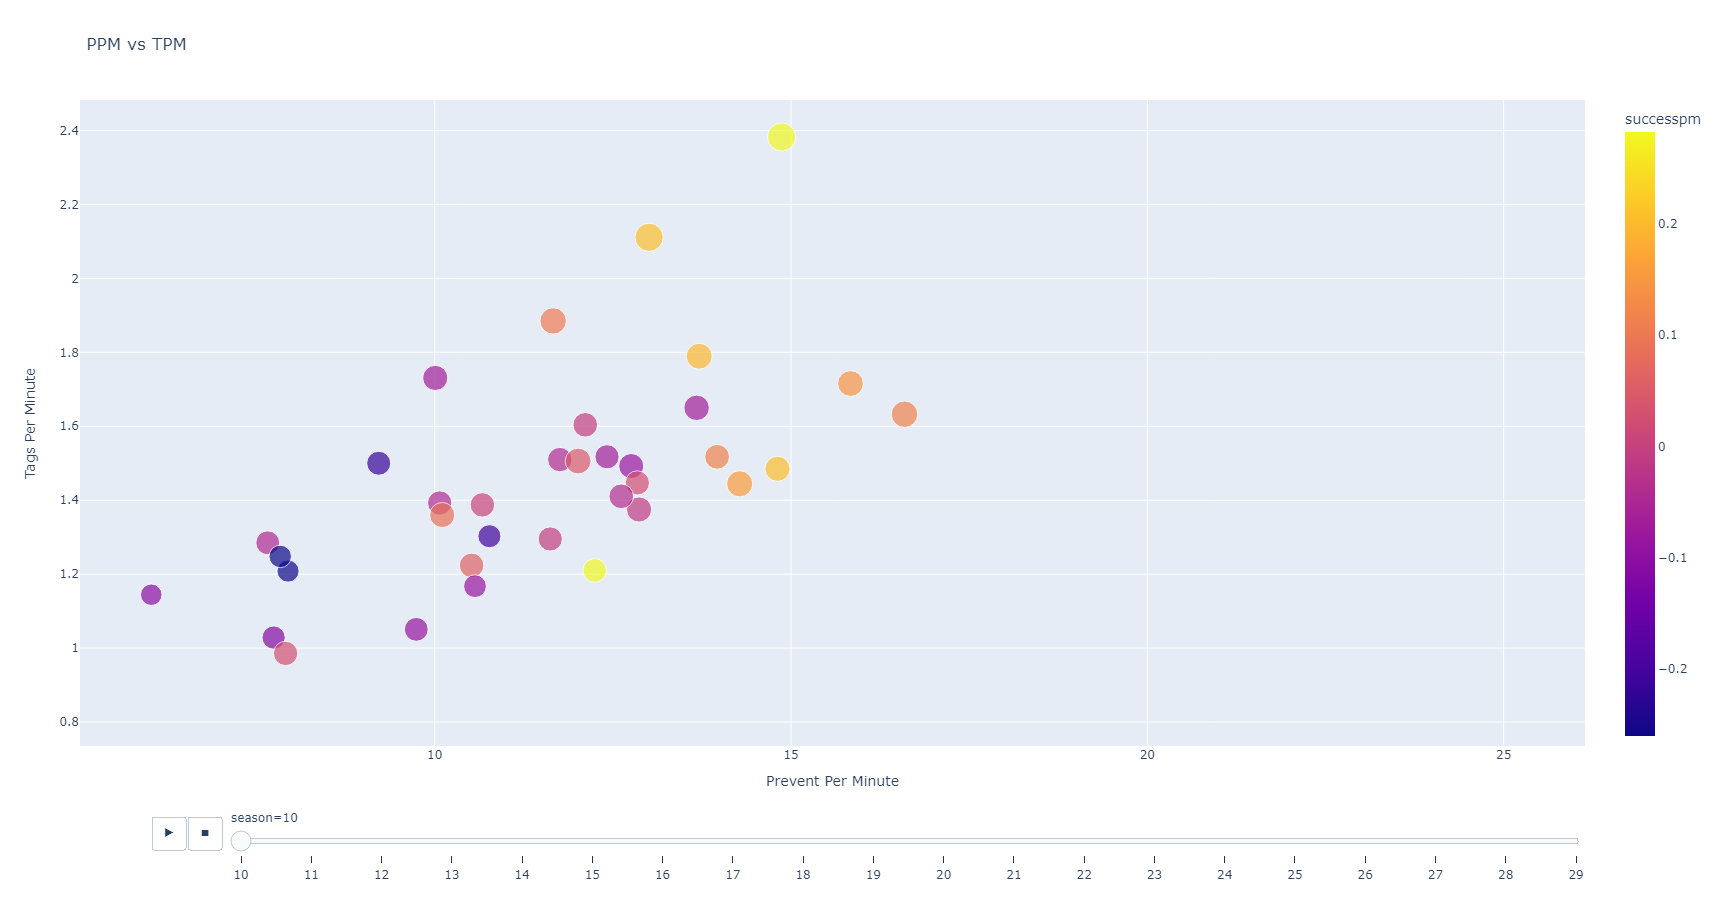

In [142]:
ppm_tpm_D = px.scatter(MLTP_D, x = "ppm", y = "tpm",
size = "scorepm", color = "successpm", animation_frame = "season",
hover_data = ["player"],
labels = {'ppm': 'Prevent Per Minute', 'tpm': 'Tags Per Minute'},
title = 'PPM vs TPM')

ppm_tpm_D.update_xaxes(range = [MLTP_D['ppm'].min() - 1, MLTP_D['ppm'].max() + 1])
ppm_tpm_D.update_yaxes(range = [MLTP_D['tpm'].min() - 0.1, MLTP_D['tpm'].max() + 0.1])

ppm_tpm_D.update_layout(scene=dict(xaxis=dict(title='Prevent Per Minute'),
yaxis=dict(title='Tags Per Minute')), height = 900)
ppm_tpm_D.show()

Let's zoom out from our more granular season view and take a gander at the bigger picture by combining the observations from each season into only two slices, Dallas vs no Dallas servers.

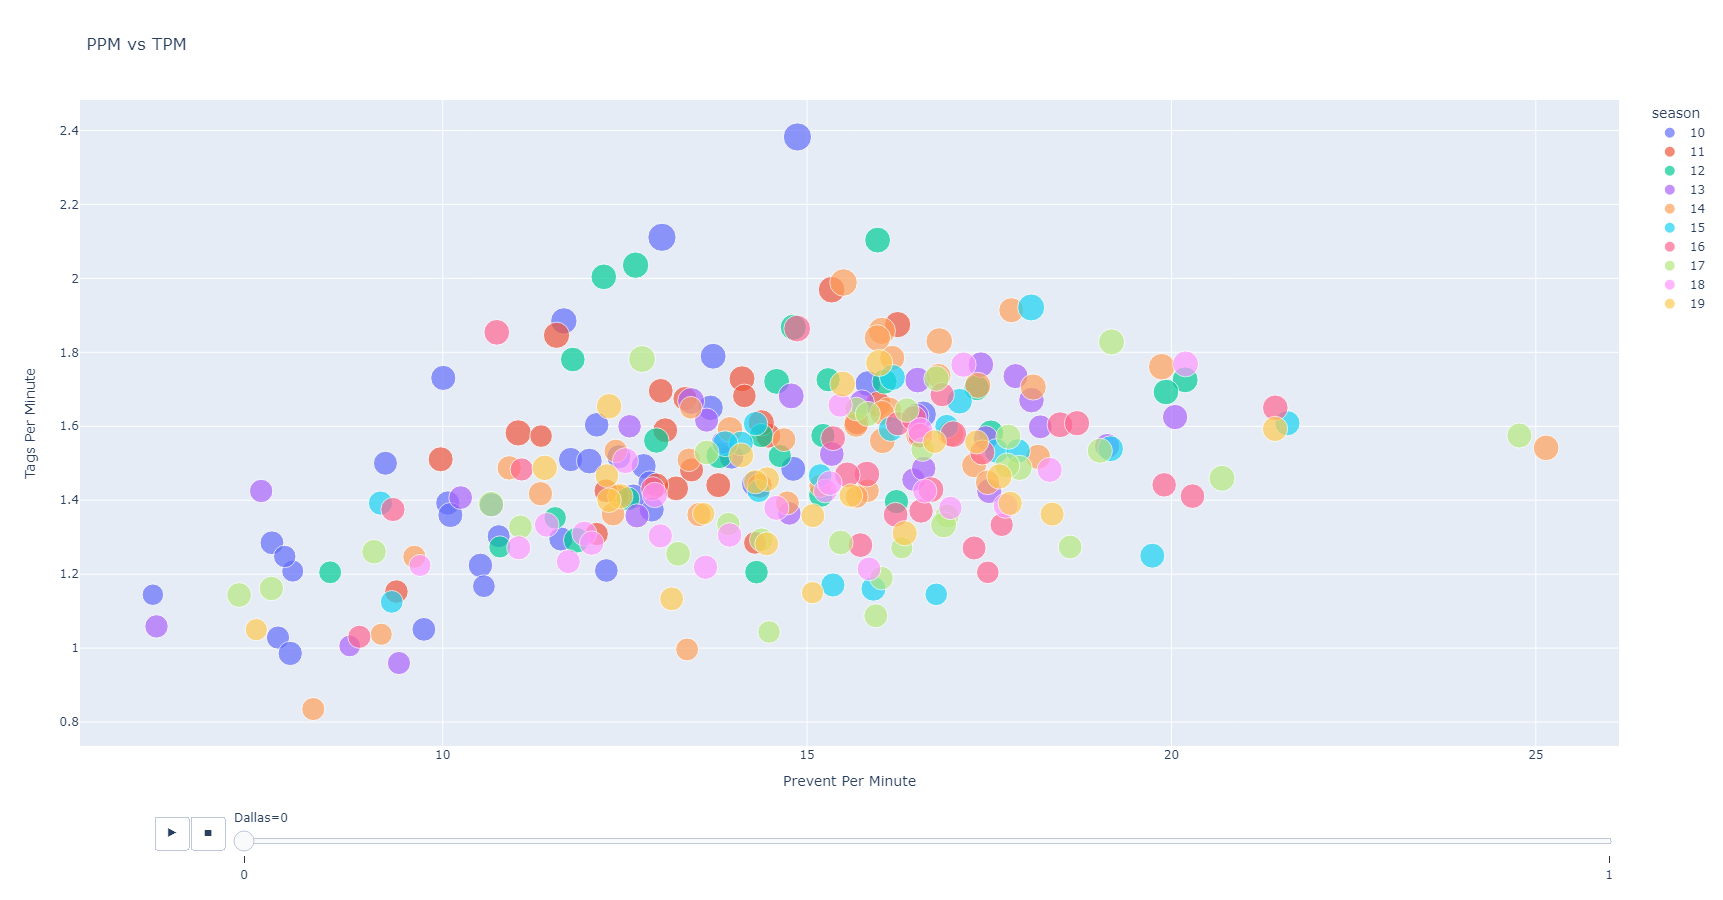

In [143]:
ppm_tpm_D_all = px.scatter(MLTP_D, x = "ppm", y = "tpm",
size = "scorepm", color = "season", animation_frame = "Dallas",
hover_data = ["player"],
labels = {'ppm': 'Prevent Per Minute', 'tpm': 'Tags Per Minute'},
title = 'PPM vs TPM')

ppm_tpm_D_all.update_xaxes(range = [MLTP_D['ppm'].min() - 1, MLTP_D['ppm'].max() + 1])
ppm_tpm_D_all.update_yaxes(range = [MLTP_D['tpm'].min() - 0.1, MLTP_D['tpm'].max() + 0.1])

ppm_tpm_D_all.update_layout(scene=dict(xaxis=dict(title='Prevent Per Minute'),
yaxis=dict(title='Tags Per Minute')), height = 900)
ppm_tpm_D_all.show()

Interestingly, the prevent numbers seem to have shrunk down over time. There are a handful of data points, about a dozen, crossing the 20 PPM barrier in the seasons which were played on home servers and even a few points all the way up near 25 PPM. Yet for the Dallas seasons, only twice did a player achieve 20 PPM. There is a similar phenomenon present with the tag numbers; a decent number of players used to hit around or above 2 tags per minute, yet only once did a player achieve that on Dallas servers. Let's move on to the revamped offense chart.

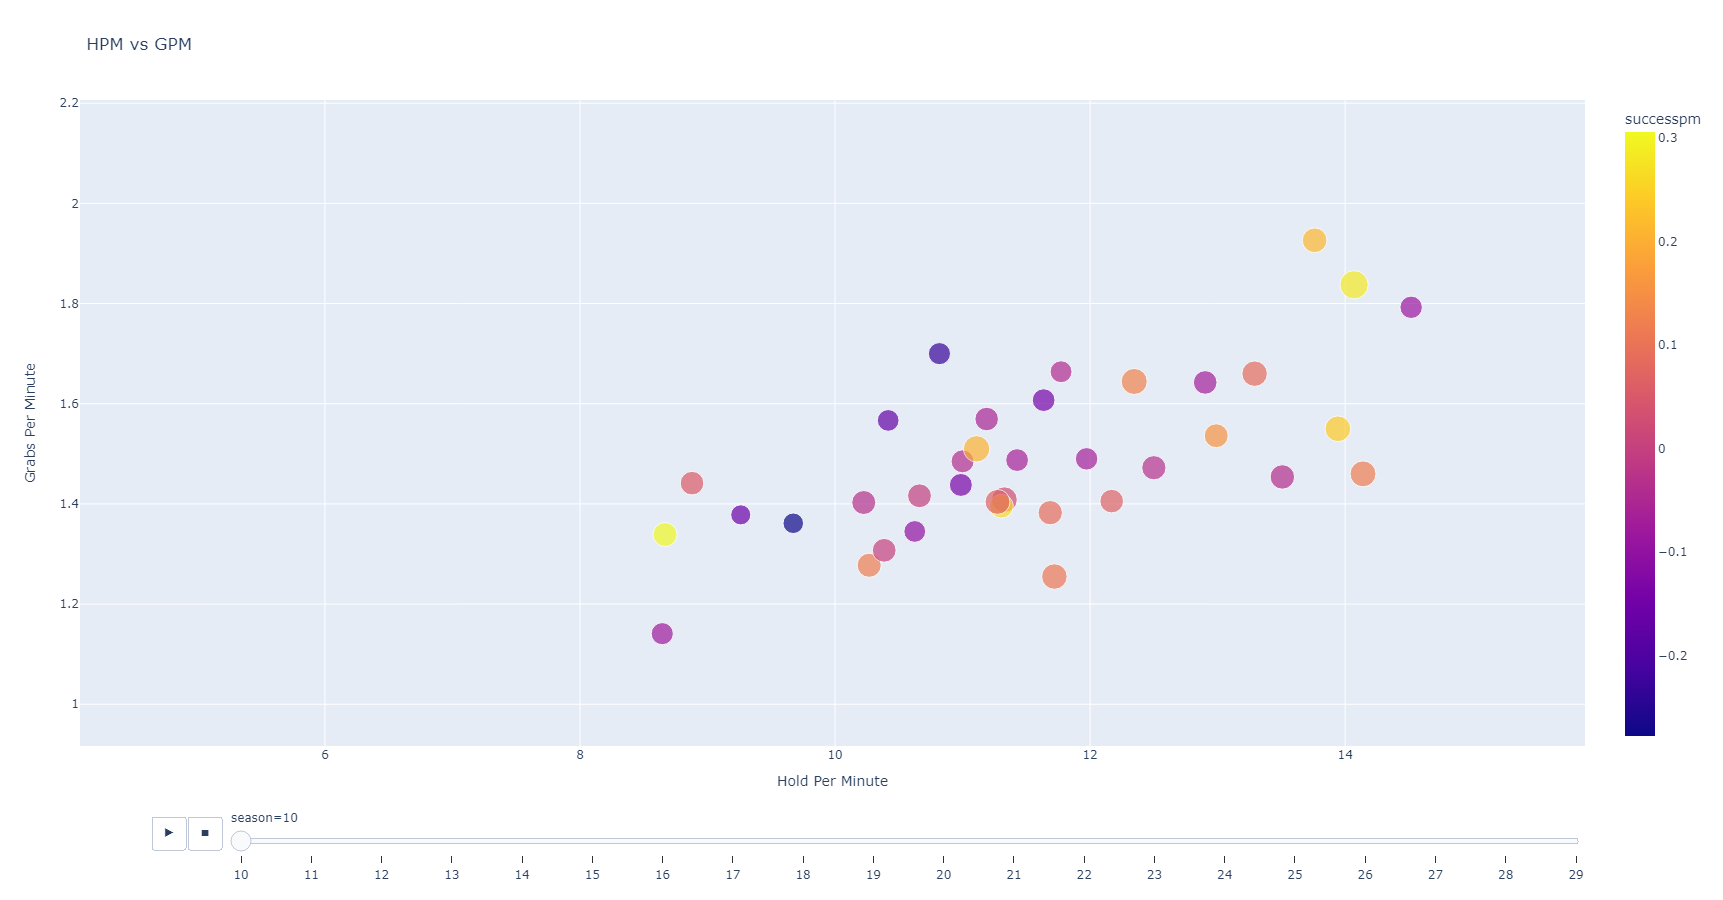

In [144]:
hpm_O = px.scatter(MLTP_O, x = "hpm", y = "gpm",
size = "scorepm", color = "successpm", animation_frame = "season",
hover_data = ["player"],
labels = {'hpm': 'Hold Per Minute', 'gpm': 'Grabs Per Minute'},
title = 'HPM vs GPM')

hpm_O.update_xaxes(range = [MLTP_O['hpm'].min() - 1, MLTP_O['hpm'].max() + 1])
hpm_O.update_yaxes(range = [MLTP_O['gpm'].min() - 0.1, MLTP_O['gpm'].max() + 0.1])

hpm_O.update_layout(scene=dict(xaxis=dict(title='Hold Per Minute'),
yaxis=dict(title='Grabs Per Minute')), height = 900)
hpm_O.show()

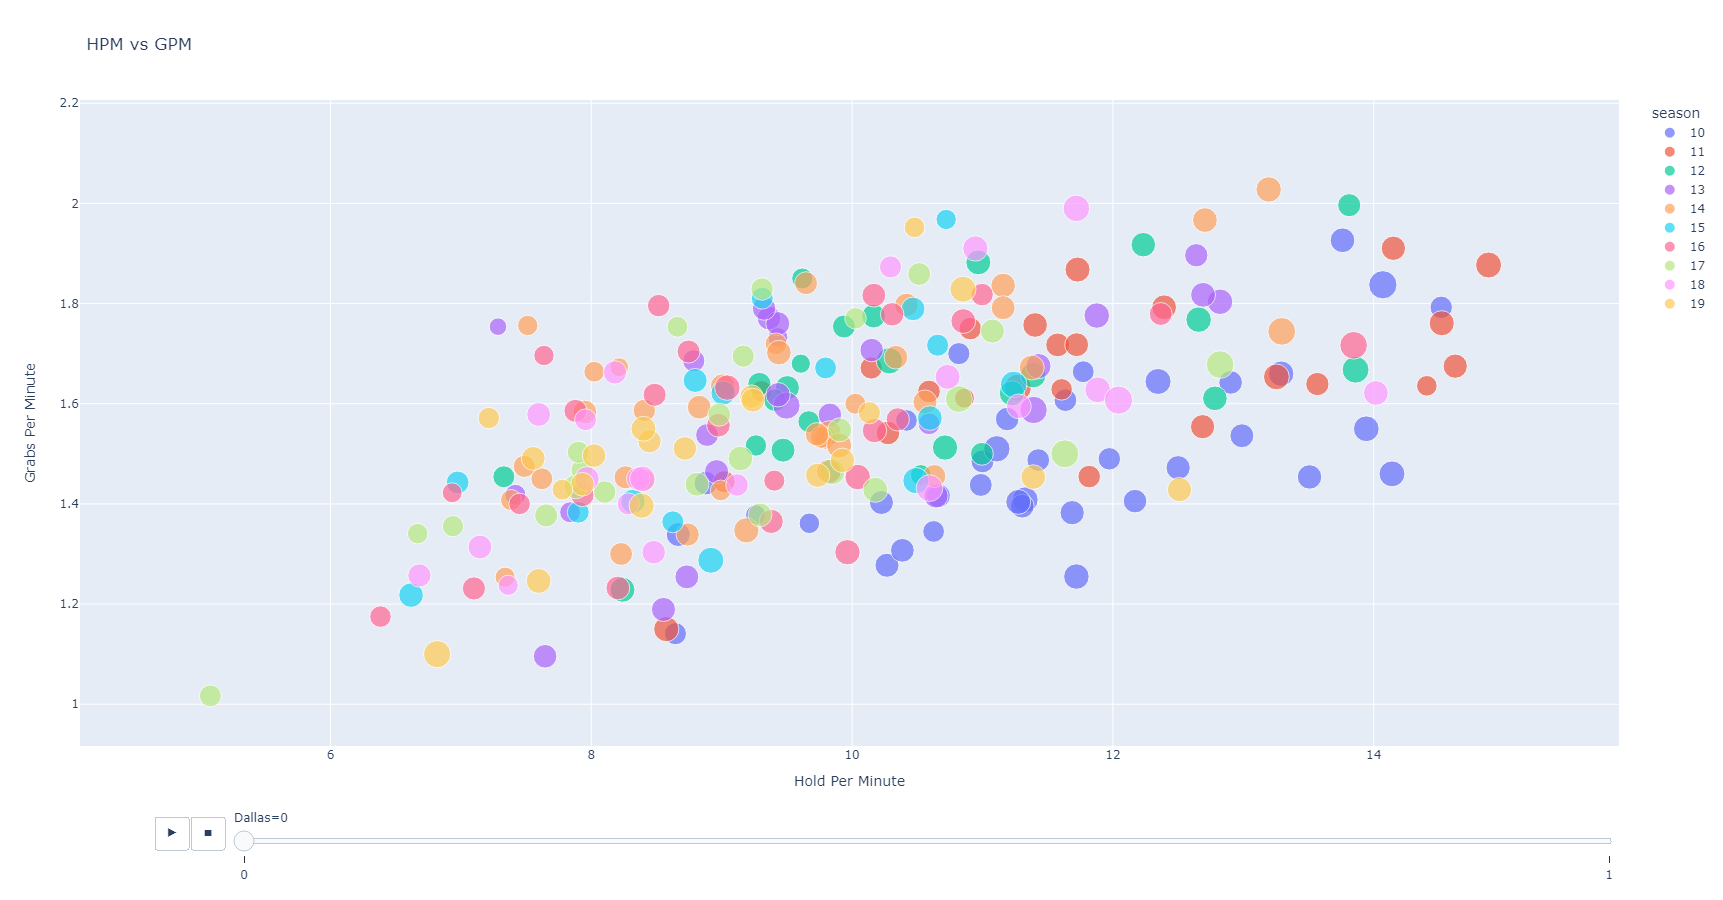

In [145]:
hpm_gpm_O_all = px.scatter(MLTP_O, x = "hpm", y = "gpm",
size = "scorepm", color = "season", animation_frame = "Dallas",
hover_data = ["player"],
labels = {'hpm': 'Hold Per Minute', 'gpm': 'Grabs Per Minute'},
title = 'HPM vs GPM')

hpm_gpm_O_all.update_xaxes(range = [MLTP_O['hpm'].min() - 1, MLTP_O['hpm'].max() + 1])
hpm_gpm_O_all.update_yaxes(range = [MLTP_O['gpm'].min() - 0.1, MLTP_O['gpm'].max() + 0.1])

hpm_gpm_O_all.update_layout(scene=dict(xaxis=dict(title='Hold Per Minute'),
yaxis=dict(title='Grabs Per Minute')), height = 900)
hpm_gpm_O_all.show()

One might intuitively expect that if players were getting less prevent (meaning their flag was taken) and getting less tags (tagging a flag carrier will send the flag back to the base), that there was more flag grabbing occuring and offenders were getting better at evading defenders, causing their grabs and hold to rise. Shockingly, both hold and grabs have been on the decline over the seasons as well.

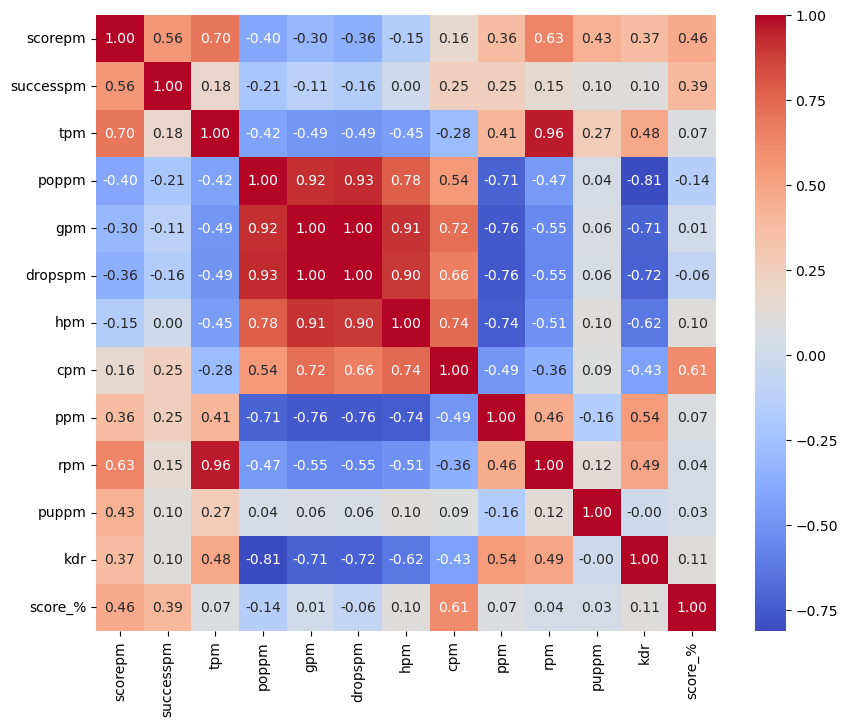

In [146]:
D_corr_matrix = MLTP_D.corr(numeric_only = True)
plt.figure(figsize=(10, 8))
sns.heatmap(D_corr_matrix, annot = True, fmt = '.2f', cmap = 'coolwarm')
plt.show()

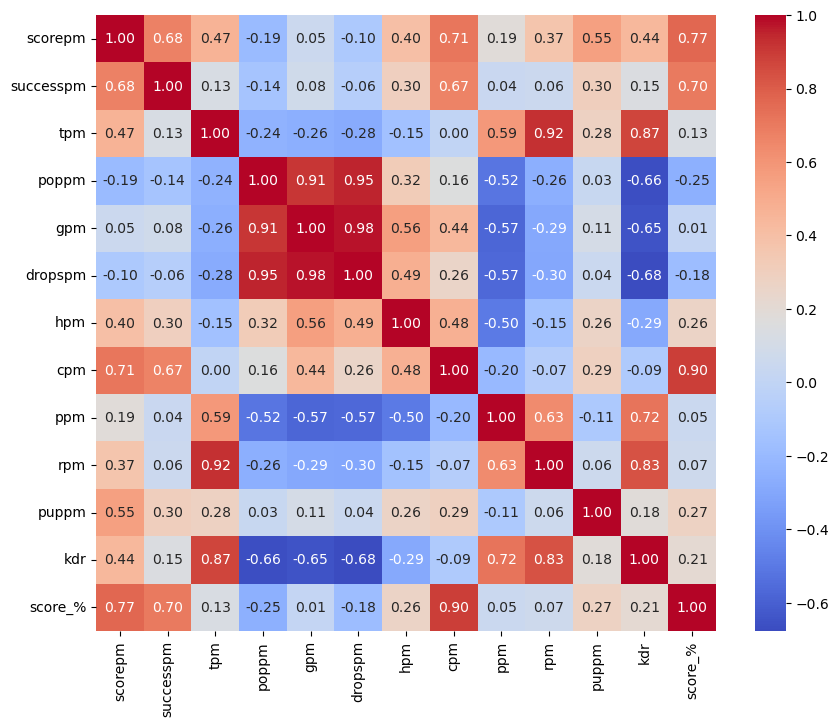

In [147]:
O_corr_matrix = MLTP_O.corr(numeric_only = True)
plt.figure(figsize = (10, 8))
sns.heatmap(O_corr_matrix, annot = True, fmt = '.2f', cmap = 'coolwarm')
plt.show()

Checking out our new correlation matrices shows that we have removed a nontrivial portion of the highly correlated features, although some of them do remain. We shall elect not to prune any more of them at present based on our SME's understanding of the nuances for each statistic. 

In [148]:
D_numeric_cols = MLTP_D.select_dtypes(include = ['int64', 'float64']).columns
print(D_numeric_cols)

D_numeric_cols = D_numeric_cols.delete(D_numeric_cols.get_loc('successpm'))

print(D_numeric_cols)

# Create a DataFrame to store the VIF values
D_vif = pd.DataFrame(columns = ['feature', 'VIF'])

# Calculate the VIF for each feature and insert into VIF df
for i, col in enumerate(D_numeric_cols):
    vif = variance_inflation_factor(MLTP_D[D_numeric_cols].values, i)
    D_vif.loc[i] = [col, vif]

# View the VIF DataFrame
print(D_vif)

Index(['scorepm', 'successpm', 'tpm', 'poppm', 'gpm', 'dropspm', 'hpm', 'cpm',
       'ppm', 'rpm', 'puppm', 'kdr', 'score_%'],
      dtype='object')
Index(['scorepm', 'tpm', 'poppm', 'gpm', 'dropspm', 'hpm', 'cpm', 'ppm', 'rpm',
       'puppm', 'kdr', 'score_%'],
      dtype='object')
    feature           VIF
0   scorepm    567.785449
1       tpm    867.330905
2     poppm    214.663614
3       gpm  13532.378418
4   dropspm  11883.515078
5       hpm     74.445122
6       cpm    125.118248
7       ppm     72.076194
8       rpm    716.768689
9     puppm     47.976348
10      kdr     11.576986
11  score_%     26.703743


In [149]:
O_numeric_cols = MLTP_O.select_dtypes(include = ['int64', 'float64']).columns
print(O_numeric_cols)

O_numeric_cols = O_numeric_cols.delete(O_numeric_cols.get_loc('successpm'))

print(O_numeric_cols)

# Create a DataFrame to store the VIF values
O_vif = pd.DataFrame(columns = ['feature', 'VIF'])

# Calculate the VIF for each feature and insert into VIF df
for i, col in enumerate(O_numeric_cols):
    vif = variance_inflation_factor(MLTP_O[O_numeric_cols].values, i)
    O_vif.loc[i] = [col, vif]

# View the VIF DataFrame
print(O_vif)

Index(['scorepm', 'successpm', 'tpm', 'poppm', 'gpm', 'dropspm', 'hpm', 'cpm',
       'ppm', 'rpm', 'puppm', 'kdr', 'score_%'],
      dtype='object')
Index(['scorepm', 'tpm', 'poppm', 'gpm', 'dropspm', 'hpm', 'cpm', 'ppm', 'rpm',
       'puppm', 'kdr', 'score_%'],
      dtype='object')
    feature           VIF
0   scorepm    400.168235
1       tpm    927.715011
2     poppm   1341.191397
3       gpm  42384.575020
4   dropspm  33718.115191
5       hpm     95.990333
6       cpm   1015.371232
7       ppm     24.226349
8       rpm    256.522960
9     puppm     58.851645
10      kdr    675.623664
11  score_%    606.739813


Tragically, the Variance Inflation Factors are quite high for both populations even after the dimensionality reduction, so we will have to resort to unsupervised learning techniques that are robust against collinearity.

Modeling + Results + Analysis

One interesting technique that we can employ here is called 'One Class Support Vector Machine', which is an unsupervised learning version of a regular SVM. It is a popular anomaly detection method that will try to build a decision boundary around a single class using a hyperplane or hypersphere, thus making every other data point not in the single class considered to be an anomaly. Similarly to SVM, OCSVM depends heavily on the choice of kernel and offers the same charcuterie board of options as its cousin (rbf, polynomial, sigmoid, linear). OCSVM is able to learn rather complicated boundaries with several of the kernel choices, making it a strong candidate for the higher dimension data we are handling here. Another important concept to keep in mind for picking a technique is its algorithmic runtime complexity paired with the size of our data. SVM and thus OCSVM are computationally quite expensive; for a dataset with k features and n observations, they will both be $O(n^3)$ for training and $O(k)$ for making a prediction on a new data point. Our datasets are only several hundred rows each, so OCSVM can handle that amount of information with practically no difference in speed for a human observer compared to a linear runtime algorithm. Let's try out several of the choices and see if we can get a reasonable separation. 

In [160]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import OneClassSVM
from sklearn.metrics import confusion_matrix, classification_report

np.random.seed(42)

# Adjust data for ingestion to OCSVM
statistics_D = MLTP_D.drop(columns = ['player', 'Dallas', 'season'])
players = MLTP_D['player']
seasons = MLTP_D['season']

# Standardize the data
scaler = StandardScaler()
data_D = scaler.fit_transform(statistics_D)

# Train the OCSVM model on the data
ocsvm = OneClassSVM(kernel = 'rbf', gamma = 0.1, nu = 0.01)
ocsvm.fit(data_D)

# Predict the anomalies
y_pred_D = ocsvm.predict(data_D)

# Print the number of anomalies detected
anomaly_total = (y_pred_D == -1).sum()
print(f'Number of anomalies detected: {anomaly_total}')

# Create a 3D interactive scatter plot of the data
fig = px.scatter_3d(MLTP_D, x = data_D[:,0], y = data_D[:,1], z = data_D[:,2], color = y_pred_D, hover_data = ['player', 'season'])
fig.update_layout(width = 800, height = 800)

fig.show()

Number of anomalies detected: 33


The eye test here is telling us that while some of the points that are marked as anomalies do appear to be outside of the main cloud of points, there are also a good number of points marked as anomalous that appear to be right in the middle of the points demarcated as belonging to the class. Our decision boundary is likely overfitting to the points and erroneously picking them out when they should be very much inside the class boundaries. Also, we see points that are quite far away from the main clustering that should probably be marked as anomalies but aren't. 

The nu hyperparameter offers the user an error vs complexity tradeoff, with larger values of nu giving robust, simpler models and smaller values of nu giving complex decision boundaries that could potentially capture critical nuances in the data but is more prone to overfitting. 

In [161]:
# Standardize the data
scaler = StandardScaler()
data_D = scaler.fit_transform(statistics_D)

for i in range(1, 6, 1):
    # Train the OCSVM model on the data
    ocsvm = OneClassSVM(kernel = 'rbf', gamma = 0.1, nu = i/10)
    ocsvm.fit(data_D)

    # Predict the anomalies
    y_pred_D = ocsvm.predict(data_D)

    # Print the number of anomalies detected
    anomaly_total = (y_pred_D == -1).sum()
    print(f'Number of anomalies detected: {anomaly_total}')

    # Create a 3D interactive scatter plot of the data
    fig2 = px.scatter_3d(MLTP_D, x = data_D[:,0], y = data_D[:,1], z = data_D[:,2], color = y_pred_D, hover_data = ['player', 'season'])
    fig2.update_layout(width = 800, height = 800)

    fig2.show()

Number of anomalies detected: 49


Number of anomalies detected: 98


Number of anomalies detected: 144


Number of anomalies detected: 188


Number of anomalies detected: 240


Our higher nu models seem to do a better job at capturing the anomalies on the fringes of the data, but they also appears to be plagued by the same issue as before, with a number of detections occuring solidly with the feature space where it should fall into the class. Let's stick with the lower nu values for now, as we would like anomalies to be actually meaningful (there should be few, not 100+).

We turn our attention to another crucial hyperparameter, gamma. Gamma is in charge of determining the width of the kernel; the larger the value of gamma, the thinner the kernel and the rougher the decision boundary is. 

In [162]:
for i in range(2, 6, 1):
    # Train the OCSVM model on the data
    ocsvm = OneClassSVM(kernel = 'rbf', gamma = i/100, nu = 0.01)
    ocsvm.fit(data_D)

    # Predict the anomalies
    y_pred_D = ocsvm.predict(data_D)

    # Print the number of anomalies detected
    anomaly_total = (y_pred_D == -1).sum()
    print(f'Number of anomalies detected: {anomaly_total}')

    # Create a 3D interactive scatter plot of the data
    fig2 = px.scatter_3d(MLTP_D, x = data_D[:,0], y = data_D[:,1], z = data_D[:,2], color = y_pred_D, hover_data = ['player', 'season'])
    fig2.update_layout(width = 800, height = 800)

    fig2.show()

Number of anomalies detected: 6


Number of anomalies detected: 10


Number of anomalies detected: 16


Number of anomalies detected: 17


Finally, we have a model that successfully only captures anomalistic points and does not misclassify data that should obviously be within the class boundary. This occurred when we had gamma = 0.02 and nu = 0.01 and a Radial Basis Function kernel. Note that while we haven't tried different kernel options yet, we have a very strong intuition that RBF is the optimal choice to fit our data. We already know from our EDA that our data certainly doesn't follow a linear relationship, and there is no evidence to suggest a polynomial or sigmoidal relationship in the data either. RBF is the most common kernel choice and it is specifically suited for high dimensional data, which is what we are dealing with. Just for posterity, we can quickly run through the other kernel options to see if one of them puts up a surprising performance.

In [163]:
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
for kernel in kernels:
    # Train the OCSVM model on the data
    ocsvm = OneClassSVM(kernel = kernel, gamma = 0.02, nu = 0.01)
    ocsvm.fit(data_D)

    # Predict the anomalies
    y_pred_D = ocsvm.predict(data_D)

    # Print the number of anomalies detected
    anomaly_total = (y_pred_D == -1).sum()
    print(f'Number of anomalies detected with {kernel} kernel: {anomaly_total}')

    # Create a 3D interactive scatter plot of the data
    fig2 = px.scatter_3d(MLTP_D, x = data_D[:,0], y = data_D[:,1], z = data_D[:,2], color = y_pred_D, hover_data = ['player', 'season'])
    fig2.update_layout(width = 800, height = 800)

    fig2.show()

Number of anomalies detected with linear kernel: 133


Number of anomalies detected with poly kernel: 372


Number of anomalies detected with rbf kernel: 6


Number of anomalies detected with sigmoid kernel: 5


As expected, the other kernel functions all performed quite poorly on the data since they are incompatible with the true nature of the dataset. Now, we're going to mix another technique into the fold to see if we can get an even better result. Although our current model passes the eye test for classifying correctly, our SME believes that the structure of the data point cloud is failing to show the best performances of the truly great players. We shall incorporate even more feature space shrinking by passing the observations through Principal Component Analysis, a.k.a. PCA, before piping them into OCSVM.

At its core, PCA distills a high dimensional feature space down into just a few components, which are constructed by a projection of the data onto the eigenvectors of the covariance matrix. The first PC captures the direction in the data that preserves the greatest amount of variance, the second PC captures the direction in the data that preserves the second greatest amount of variance, constrained by being required to be orthogonal to the first PC, and so on. This allows the chosen components to preserve a large percentage of the variation in the original dataset while drastically cutting down the dimensionality of the data. We will choose to reduce down to just three PCs, since any higher dimension becomes demonstrably harder for humans to interpret. After all, both the beauty and strength of PCA is to allow low dimensional operations and visualization.

In [164]:
# Perform PCA
pca = PCA(n_components=3)
data_pca = pca.fit_transform(data_D)

# Train the OCSVM model on the data
ocsvm = OneClassSVM(kernel = 'rbf', gamma = 0.08, nu = 0.01)
ocsvm.fit(data_pca)

# Predict the anomalies
y_pred = ocsvm.predict(data_pca)

# Create a 3D scatter plot of the data
fig = px.scatter_3d(MLTP_D, x = data_pca[:,0], y = data_pca[:,1], z = data_pca[:,2], color = y_pred, hover_data = ['player', 'season'])
fig.update_layout(width = 800, height = 800)

fig.show()

The structure of the data finally seems to match up with the points that our SME advises should be considered anomalies. Notice that there is a cluster of points very deep along the 1st principal component axes comprised of data points only from Syniikal/TomatoFarmer/PingPrisoner. These points are all from one player under different monikors, and his performances are on a completely different statistical level from every other defender, so being able to see these points forming their own microcosm away from the rest of the players is one good indicator that the structure is finally correct. Another key indicator is that many of the points on the outer edges of the big cluster that are closest to the Syniikal pile are a litany of other elite players from their most memorable performances, including but not limited to S10 Griefseeds, S10 Abe Lincoln, S14 badger, S14 Intercest, S25 Wayne, and S21 meX. Let's take a look at the list of players ranked by how anomalous their statistical performances were considered by the model.

In [165]:
# Compute the decision function values for each data point
decision_values = ocsvm.decision_function(data_pca)

# Rank the data points by the absolute value of their decision function
ranked_indices = np.argsort(decision_values)[::-1]

# Print the top 10 anomalies
top_anomalies = ranked_indices[:30]
print(top_anomalies)
for i in top_anomalies:
    player = players[i]
    season = seasons[i]
    decision_value = decision_values[i]
    print(f"{player} in season {season} is an anomaly with decision function value {decision_value:.2f}")

[382  87 210  57 276  83 375 476 317 199 469 321 269 319 304  86 474 290
   8 369 366  95 139 395 222 154 352 341 188 367]
Meg in season 25 is an anomaly with decision function value 0.13
Daffodildo in season 13 is an anomaly with decision function value 0.12
thenewguy. in season 17 is an anomaly with decision function value 0.11
ComfortFlair in season 11 is an anomaly with decision function value 0.11
Abe Lincoln in season 20 is an anomaly with decision function value 0.11
young savage in season 12 is an anomaly with decision function value 0.11
glob. in season 24 is an anomaly with decision function value 0.10
flaccid trip in season 29 is an anomaly with decision function value 0.10
NEB. in season 21 is an anomaly with decision function value 0.10
CB13 in season 17 is an anomaly with decision function value 0.10
ASAP in season 29 is an anomaly with decision function value 0.10
GeT_RiGhT in season 21 is an anomaly with decision function value 0.10
CHEEZEDOODLE in season 19 is an anoma

Let's also check on the other kernel types for our preprocessed PCA OCSVM models just to make sure RBF kernel still looks like our winning horse.

In [166]:
# Train the OCSVM model on the data
ocsvm = OneClassSVM(kernel='linear', gamma = 0.02, nu = 0.01)
ocsvm.fit(data_pca)

# Predict the anomalies
y_pred = ocsvm.predict(data_pca)

# Create a 3D scatter plot of the data
fig = px.scatter_3d(MLTP_D, x = data_pca[:,0], y = data_pca[:,1], z = data_pca[:,2], color = y_pred, hover_data = ['player', 'season'])
fig.update_layout(width = 800, height = 800)

fig.show()

In [167]:
# Train the OCSVM model on the data
ocsvm = OneClassSVM(kernel = 'poly', gamma = 0.02, nu = 0.01)
ocsvm.fit(data_pca)

# Predict the anomalies
y_pred = ocsvm.predict(data_pca)

# Create a 3D scatter plot of the data
fig = px.scatter_3d(MLTP_D, x = data_pca[:,0], y = data_pca[:,1], z = data_pca[:,2], color = y_pred, hover_data = ['player', 'season'])
fig.update_layout(width = 800, height = 800)

fig.show()

In [168]:
# Train the OCSVM model on the data
ocsvm = OneClassSVM(kernel = 'sigmoid', gamma = 0.02, nu = 0.01)
ocsvm.fit(data_pca)

# Predict the anomalies
y_pred = ocsvm.predict(data_pca)

# Create a 3D scatter plot of the data
fig = px.scatter_3d(MLTP_D, x = data_pca[:,0], y = data_pca[:,1], z = data_pca[:,2], color = y_pred, hover_data = ['player', 'season'])
fig.update_layout(width = 800, height = 800)

fig.show()

As we suspected, RBF is still the clear winner. Let's take a look at another visualization tool, a Parallel Coordinates plot. This tool allows us to easily visualize higher dimensional data in a way that our human brains can readily interpret despite being constrained to only three spatial dimensions of comprehension. This is done by flattening a n-dimensional visualization into a 2-D representation of n connected dimensions. For our purposes, this is a great tool for seeing how dominant some of the best performances actually were, but unfortunately it doesn't yet support the hover function so the lines are not labeled with the player names and seasons. Our SME knows which lines for the top dozen or so correspond to each player/season combination and confirms that these are the same points marked as either an anomlay or they are in the Syniikal cluster.

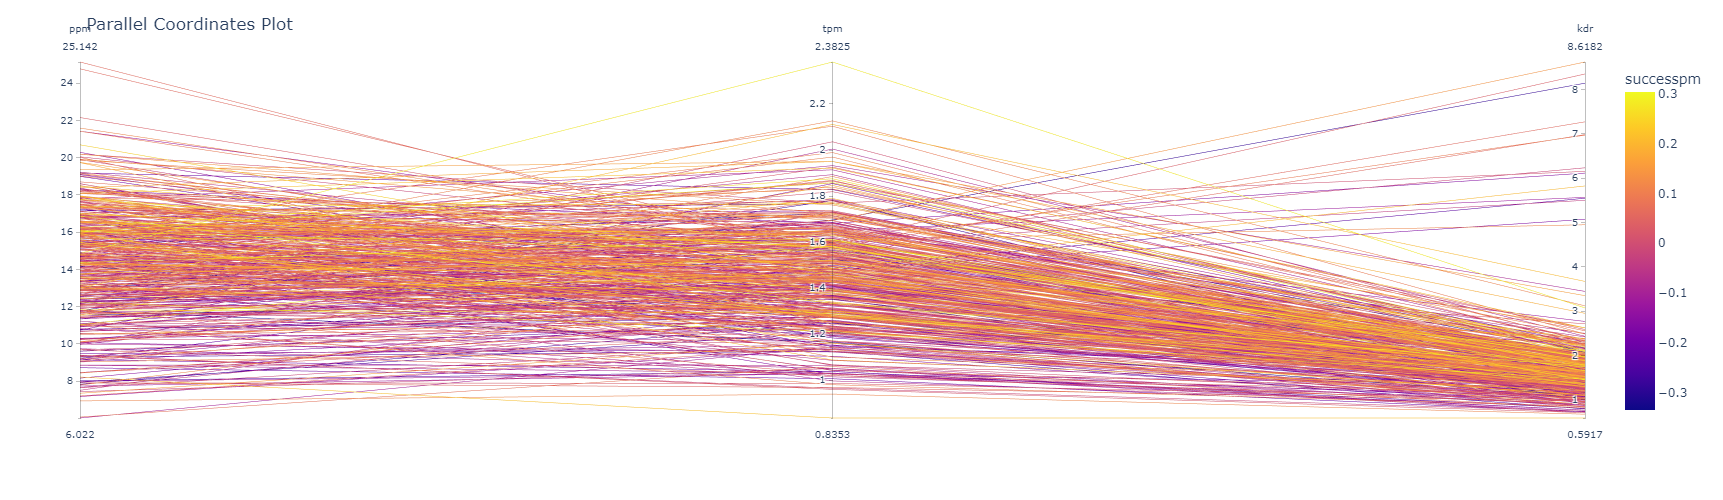

In [159]:
# Create parallel coordinates plot using plotly express
fig = px.parallel_coordinates(MLTP_D, color = "successpm", 
                              dimensions = ["ppm", "tpm", "kdr"])
                              
                              

# Customize the plot
fig.update_layout(width = 800, height = 500, title = "Parallel Coordinates Plot")
fig.update_traces(line=dict(color=MLTP_D["successpm"], colorscale="Viridis", 
                             showscale=True, reversescale=True))

# Show the plot
fig.show()

Conclusion

In the future, we would definitely like to revisit the same concept but check out the offender side of the analysis. It would be interesting to see if the same type of model would be the best fit for that population of players or if an entirely different kernel or even machine learning technique would be required. Overall, the anomaly detection model with the feature space reduction through PCA and then piped into OCSVM with a gamma of 0.02, nu of 0.01, and an RBF kernel did an excellent job at detecting anomalies. The main weakness that our best model (and in fact all of our attempted models) had was that it was unable to discern most of the performances by Syniikal as statistical anomalies. This is due to the high number of seasons he played at an astounding level, which caused a cluster of over a dozen data points to form a second cluster away from the main data cloud in the three dimensional scatterplot. Because there were so many points, the models were encouraged to draw the decision boundary farther out in that direction to capture that variation and therefore only a few of the Syniikal cluster points were marked as outside of the class when realistically all of them should have been outside of the class. 

In unsupervised learning, there isn't always a test set to validate against like there will be in a classroom setting when labeled test sets are given freely to check against. Measures that could typically be applied to unsueprvised methods such as Silhouette score (how tightly points are clustered in each class - doesn't work with one class), Elbow graph (determine optimal number of clusters - we are mandating a single cluster), and cross validation/F1 score/accuracy/recall/precision/ROC/AUC (no ground truth test set to compare to) all fall short. In the real world, we are often forced to get a little more creative than that, and this is a perfect example of an opportunity of how to incorporate that. A way to improve this in the future could be to recognize that Syniikal points are all anomalies, remove them from the training data, and then split some of the remaining data off to use in conjunction with the Syniikal data as a testing set. Not only will training a model without Syniikal data make the class boundaries more representative of what an anomaly should look like, but it also allows us to run the Syniikal data as a test against the model. If the model doesn't identify every single point as an anomaly, then the model structure certainly has not accurately reflected the truth. Another potentially useful tool would be to sit down with a focus group of elite players and have them label a test set of randomly pulled performances plus all of the Syniikal points, thereby creating a ground truth to measure against in the future.